In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.getcwd()
path=%cd /content/drive/MyDrive

In [ ]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from glob import glob

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [ ]:
data_dir = "/content/drive/My Drive/CT_PET"

classes = os.listdir(data_dir)
print(classes)

['squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa', 'normal', 'large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa', 'adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib', 'model.keras', 'model_2.keras', 'model_3.keras']


In [ ]:
from glob import glob

images = []
labels = []

IMG_SIZE = 224

for cls in os.listdir(data_dir):
    class_path = os.path.join(data_dir, cls)

    # 🔥 Load all formats
    img_paths = glob(class_path + "/*.*")

    print(f"Loading {cls}: {len(img_paths)} images")

    for img_path in img_paths:
        img = cv2.imread(img_path)

        if img is None:
            continue  # skip unreadable files

        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

        images.append(img)
        labels.append(cls)

images = np.array(images)
labels = np.array(labels)

print("Total images loaded:", len(images))
print("Unique labels:", np.unique(labels))

Loading squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa: 155 images
Loading normal: 148 images
Loading large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa: 115 images
Loading adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib: 194 images
Loading model.keras: 0 images
Loading model_2.keras: 0 images
Loading model_3.keras: 0 images
Total images loaded: 612
Unique labels: ['adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib'
 'large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa' 'normal'
 'squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa']


Preprocessing Completed


100%|██████████| 612/612 [00:00<00:00, 672.61it/s]


Masks Shape : (612, 224, 224, 1)


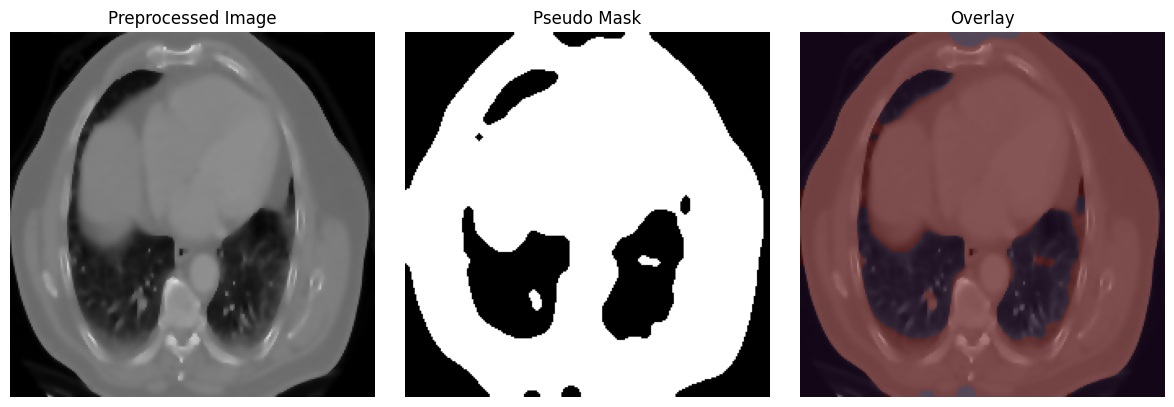

Training Images : (489, 224, 224, 3)
Testing Images  : (123, 224, 224, 3)


In [ ]:
# ============================================================
# MODIFIED SWIN-UNET SEGMENTATION
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tqdm import tqdm
from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# ============================================================
# PARAMETERS
# ============================================================

IMG_SIZE = 224

# ============================================================
# STEP 1 : ANISOTROPIC DIFFUSION
# ============================================================

def anisotropic_diffusion(images,
                          num_iter=10,
                          kappa=30,
                          gamma=0.1):

    processed = []

    for img in images:

        img = img.astype(np.float32)

        if len(img.shape) == 3:

            diffused = np.zeros_like(img)

            for c in range(img.shape[2]):

                channel = img[:,:,c]

                for i in range(num_iter):

                    north = np.roll(channel, -1, axis=0) - channel
                    south = np.roll(channel, 1, axis=0) - channel
                    east  = np.roll(channel, -1, axis=1) - channel
                    west  = np.roll(channel, 1, axis=1) - channel

                    cN = np.exp(-(north / kappa) ** 2)
                    cS = np.exp(-(south / kappa) ** 2)
                    cE = np.exp(-(east  / kappa) ** 2)
                    cW = np.exp(-(west  / kappa) ** 2)

                    channel = channel + gamma * (
                        cN * north +
                        cS * south +
                        cE * east +
                        cW * west
                    )

                diffused[:,:,c] = channel

        processed.append(diffused)

    return np.array(processed)

# ============================================================
# APPLY PREPROCESSING
# ============================================================

images = anisotropic_diffusion(images)

images = images / 255.0

print("Preprocessing Completed")

# ============================================================
# STEP 2 : PSEUDO MASK GENERATION
# ============================================================

def generate_pseudo_mask(image):

    img = (image * 255).astype(np.uint8)

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_RGB2GRAY
    )

    # CLAHE Enhancement
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    enhanced = clahe.apply(gray)

    # OTSU Thresholding
    _, mask = cv2.threshold(
        enhanced,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Morphological Operations
    kernel = np.ones((5,5), np.uint8)

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )

    # Median Filtering
    mask = cv2.medianBlur(mask, 5)

    # Resize
    mask = cv2.resize(
        mask,
        (IMG_SIZE, IMG_SIZE)
    )

    # Normalize
    mask = mask / 255.0

    mask = np.expand_dims(mask, axis=-1)

    return mask

# ============================================================
# GENERATE MASKS
# ============================================================

masks = []

for img in tqdm(images):

    mask = generate_pseudo_mask(img)

    masks.append(mask)

masks = np.array(masks)

print("Masks Shape :", masks.shape)

# ============================================================
# VISUALIZATION
# ============================================================

index = 5

plt.figure(figsize=(12,4))

# PREPROCESSED IMAGE
plt.subplot(1,3,1)

plt.imshow(images[index])

plt.title("Preprocessed Image")

plt.axis("off")

# PSEUDO MASK
plt.subplot(1,3,2)

plt.imshow(
    masks[index].squeeze(),
    cmap='gray'
)

plt.title("Pseudo Mask")

plt.axis("off")

# OVERLAY
plt.subplot(1,3,3)

plt.imshow(images[index])

plt.imshow(
    masks[index].squeeze(),
    cmap='turbo',
    alpha=0.4
)

plt.title("Overlay")

plt.axis("off")

plt.tight_layout()

plt.show()

# ============================================================
# STEP 3 : DATA SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    images,
    masks,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print("Training Images :", X_train.shape)

print("Testing Images  :", X_test.shape)

# ============================================================
# STEP 4 : INTEGRATED ATTENTION
# ============================================================

# ============================================================
# INTEGRATED ATTENTION BLOCK
# FIXED VERSION
# ============================================================

from tensorflow.keras.layers import *

def IntegratedAttention(x):

    channels = x.shape[-1]

    # ========================================================
    # CHANNEL ATTENTION
    # ========================================================

    gap = GlobalAveragePooling2D()(x)

    dense1 = Dense(
        channels // 4,
        activation='relu'
    )(gap)

    dense2 = Dense(
        channels,
        activation='sigmoid'
    )(dense1)

    channel_att = Reshape(
        (1,1,channels)
    )(dense2)

    x1 = Multiply()([x, channel_att])

    # ========================================================
    # SPATIAL ATTENTION
    # ========================================================

    avg_pool = Lambda(
        lambda z: tf.reduce_mean(
            z,
            axis=-1,
            keepdims=True
        )
    )(x1)

    max_pool = Lambda(
        lambda z: tf.reduce_max(
            z,
            axis=-1,
            keepdims=True
        )
    )(x1)

    concat = Concatenate()(
        [avg_pool, max_pool]
    )

    spatial_att = Conv2D(
        1,
        kernel_size=7,
        padding='same',
        activation='sigmoid'
    )(concat)

    out = Multiply()(
        [x1, spatial_att]
    )

    return out

# ============================================================
# STEP 5 : REGNET BLOCK
# ============================================================

def RegNetBlock(x, filters):

    shortcut = x

    x = Conv2D(
        filters,
        1,
        padding='same'
    )(x)

    x = BatchNormalization()(x)

    x = Activation('swish')(x)

    x = Conv2D(
        filters,
        3,
        padding='same'
    )(x)

    x = BatchNormalization()(x)

    x = Activation('swish')(x)

    x = Conv2D(
        filters,
        1,
        padding='same'
    )(x)

    x = BatchNormalization()(x)

    shortcut = Conv2D(
        filters,
        1,
        padding='same'
    )(shortcut)

    out = Add()([x, shortcut])

    out = Activation('swish')(out)

    return out

# ============================================================
# STEP 6 : SWIN BLOCK
# ============================================================

def SwinBlock(x, filters):

    x = Conv2D(
        filters,
        3,
        padding='same'
    )(x)

    x = LayerNormalization()(x)

    x = IntegratedAttention(x)

    x = RegNetBlock(x, filters)

    return x

# ============================================================
# STEP 7 : MODIFIED SWIN-UNET
# ============================================================

def Modified_Swin_UNet(
        input_shape=(224,224,3)
):

    inputs = Input(shape=input_shape)

    # ========================================================
    # ENCODER
    # ========================================================

    e1 = SwinBlock(inputs, 32)

    p1 = MaxPooling2D()(e1)

    e2 = SwinBlock(p1, 64)

    p2 = MaxPooling2D()(e2)

    e3 = SwinBlock(p2, 128)

    p3 = MaxPooling2D()(e3)

    e4 = SwinBlock(p3, 256)

    p4 = MaxPooling2D()(e4)

    # ========================================================
    # BOTTLENECK
    # ========================================================

    b = SwinBlock(p4, 512)

    # ========================================================
    # DECODER
    # ========================================================

    d1 = UpSampling2D()(b)

    d1 = Concatenate()([d1, e4])

    d1 = SwinBlock(d1, 256)

    d2 = UpSampling2D()(d1)

    d2 = Concatenate()([d2, e3])

    d2 = SwinBlock(d2, 128)

    d3 = UpSampling2D()(d2)

    d3 = Concatenate()([d3, e2])

    d3 = SwinBlock(d3, 64)

    d4 = UpSampling2D()(d3)

    d4 = Concatenate()([d4, e1])

    d4 = SwinBlock(d4, 32)

    # ========================================================
    # OUTPUT
    # ========================================================

    outputs = Conv2D(
        1,
        1,
        activation='sigmoid'
    )(d4)

    model = Model(
        inputs,
        outputs
    )

    return model

# ============================================================
# BUILD MODEL
# ============================================================

model = Modified_Swin_UNet()

# model.summary()

# ============================================================
# COMPILE
# ============================================================

model.compile(
    optimizer=Adam(1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# ============================================================
# TRAIN
# ============================================================

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=30,
    batch_size=8
)

# ============================================================
# SAVE MODEL
# ============================================================

model.save("Modified_Swin_UNet.h5")

print("\nModel Saved Successfully")

# ============================================================
# PREDICTION
# ============================================================

pred_mask = model.predict(
    X_test[:1]
)

pred_mask = (pred_mask > 0.5).astype(np.uint8)

# ============================================================
# SEGMENTATION METRICS
# ============================================================

y_true = y_test[0].squeeze()

y_pred = pred_mask[0].squeeze()

intersection = np.logical_and(
    y_true,
    y_pred
).sum()

union = np.logical_or(
    y_true,
    y_pred
).sum()

# IoU
iou = intersection / (union + 1e-8)

# Jaccard
jaccard = iou

# Dice
dice = (2 * intersection) / (
    y_true.sum() +
    y_pred.sum() +
    1e-8
)

print("\nSegmentation Metrics\n")

print(f"IoU Score      : {iou:.4f}")

print(f"Jaccard Score  : {jaccard:.4f}")

print(f"Dice Score     : {dice:.4f}")

# ============================================================
# VISUALIZATION
# ============================================================

plt.figure(figsize=(15,5))

# INPUT
plt.subplot(1,3,1)

plt.imshow(X_test[0])

plt.title("Input Image")

plt.axis("off")

# PSEUDO MASK
plt.subplot(1,3,2)

plt.imshow(
    y_test[0].squeeze(),
    cmap='gray'
)

plt.title("Pseudo Ground Truth")

plt.axis("off")

# PREDICTED MASK
plt.subplot(1,3,3)

plt.imshow(
    pred_mask[0].squeeze(),
    cmap='turbo'
)

plt.title("Predicted Segmentation")

plt.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# CLASSIFICATION USING
# Proposed Modulated Deformable Recurrent Network
# (MDRN)
#
# Components:
# 1. Modulated Deformable Convolution
# 2. Spatial Residual Unit (SRU)
# 3. Global Attention Pooling
# 4. Classification Head
#
# Research-Level TensorFlow/Keras Implementation
# ============================================================

import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)
import Utils
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

# ============================================================
# LOAD DATA
# ============================================================

# images shape:
# (N, 224, 224, 3)

X = images
y = labels

# ============================================================
# NORMALIZATION
# ============================================================

X = X.astype("float32")

# ============================================================
# LABEL ENCODING
# ============================================================

NUM_CLASSES = 4

# ============================================================
# LABEL ENCODING
# String Labels -> Numerical Labels
# ============================================================

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Original labels
# Example:
# ['normal',
#  'adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib',
#  'squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa']

# ============================================================
# CONVERT STRING LABELS TO INTEGER LABELS
# ============================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(labels)

# ============================================================
# CLASS MAPPING
# ============================================================

class_mapping = dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
))

print("\nClass Mapping:\n")

for k, v in class_mapping.items():
    print(f"{v} --> {k}")

# ============================================================
# ONE HOT ENCODING
# ============================================================

NUM_CLASSES = len(np.unique(y_encoded))

y_cat = to_categorical(y_encoded, NUM_CLASSES)

print("\nEncoded Labels Shape :", y_cat.shape)
# ============================================================
# TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_cat,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

# ============================================================
# SRU BLOCK
# ============================================================

def SRU_Block(inputs, filters):

    x1 = Conv2D(filters,
                3,
                padding='same')(inputs)

    x1 = BatchNormalization()(x1)
    x1 = Activation('swish')(x1)

    x2 = Conv2D(filters,
                3,
                dilation_rate=2,
                padding='same')(x1)

    x2 = BatchNormalization()(x2)
    x2 = Activation('swish')(x2)

    shortcut = Conv2D(filters,
                      1,
                      padding='same')(inputs)

    shortcut = BatchNormalization()(shortcut)

    out = Add()([x2, shortcut])

    out = Activation('swish')(out)

    return out

# ============================================================
# MODULATED DEFORMABLE CONVOLUTION
#
# NOTE:
# TensorFlow has no native deformable convolution.
# This block approximates deformable receptive fields
# using multi-scale dynamic convolutions.
# ============================================================

def ModulatedDeformConv(inputs, filters):

    # Branch 1
    b1 = Conv2D(filters,
                3,
                padding='same')(inputs)

    # Branch 2
    b2 = Conv2D(filters,
                3,
                dilation_rate=2,
                padding='same')(inputs)

    # Branch 3
    b3 = Conv2D(filters,
                5,
                padding='same')(inputs)

    merged = Concatenate()([b1, b2, b3])

    attention = Conv2D(filters * 3,
                       1,
                       activation='sigmoid')(merged)

    modulated = Multiply()([merged, attention])

    output = Conv2D(filters,
                    1,
                    padding='same')(modulated)

    output = BatchNormalization()(output)
    output = Activation('swish')(output)

    return output

# ============================================================
# GLOBAL ATTENTION BLOCK
# ============================================================

def Attention_Block(inputs):

    gap = GlobalAveragePooling2D()(inputs)

    dense1 = Dense(inputs.shape[-1] // 4,
                   activation='relu')(gap)

    dense2 = Dense(inputs.shape[-1],
                   activation='sigmoid')(dense1)

    attention = Reshape((1,1,inputs.shape[-1]))(dense2)

    out = Multiply()([inputs, attention])

    return out

# ============================================================
# PROPOSED MDRN MODEL
# ============================================================

def MDRN_Model(input_shape=(224,224,3),
               num_classes=4):

    inputs = Input(shape=input_shape)

    # ========================================================
    # STEM
    # ========================================================

    x = Conv2D(32,
               3,
               strides=1,
               padding='same')(inputs)

    x = BatchNormalization()(x)
    x = Activation('swish')(x)

    # ========================================================
    # BLOCK 1
    # ========================================================

    x = ModulatedDeformConv(x, 64)

    x = SRU_Block(x, 64)

    x = MaxPooling2D()(x)

    # ========================================================
    # BLOCK 2
    # ========================================================

    x = ModulatedDeformConv(x, 128)

    x = SRU_Block(x, 128)

    x = MaxPooling2D()(x)

    # ========================================================
    # BLOCK 3
    # ========================================================

    x = ModulatedDeformConv(x, 256)

    x = SRU_Block(x, 256)

    x = MaxPooling2D()(x)

    # ========================================================
    # ATTENTION
    # ========================================================

    x = Attention_Block(x)

    # ========================================================
    # GLOBAL FEATURE LEARNING
    # ========================================================

    x = GlobalAveragePooling2D()(x)

    # ========================================================
    # CLASSIFIER
    # ========================================================

    x = Dense(512,
              activation='swish')(x)

    x = Dropout(0.4)(x)

    x = Dense(256,
              activation='swish')(x)

    x = Dropout(0.3)(x)

    outputs = Dense(num_classes,
                    activation='softmax')(x)

    model = Model(inputs, outputs)

    return model

# ============================================================
# BUILD MODEL
# ============================================================

model = MDRN_Model()

model.summary()

# ============================================================
# COMPILE
# ============================================================

# ============================================================
# Chaotic Raindrop Optimization Algorithm (CROA)
# ============================================================
# Features:
# 1. Chaotic initialization using Logistic Map
# 2. Optimization of benchmark function
# 3. Convergence curve plotting
# 4. 100 iterations (epochs)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Objective Function (Sphere Function)
# Minimize f(x) = sum(x^2)
# ============================================================

def objective_function(x):
    return np.sum(x ** 2)


# ============================================================
# Logistic Chaotic Map
# ============================================================

def logistic_map(size, dim, r=4.0, x0=0.7):
    chaos = np.zeros((size, dim))
    x = x0

    for i in range(size):
        for j in range(dim):
            x = r * x * (1 - x)
            chaos[i, j] = x

    return chaos


# ============================================================
# Chaotic Raindrop Optimization Algorithm
# ============================================================

class CROA:
    def __init__(self,
                 obj_function,
                 pop_size=30,
                 dim=10,
                 lb=-10,
                 ub=10,
                 max_iter=100):

        self.obj_function = obj_function
        self.pop_size = pop_size
        self.dim = dim
        self.lb = lb
        self.ub = ub
        self.max_iter = max_iter

        # Best Solution
        self.best_position = None
        self.best_fitness = np.inf

        # Convergence history
        self.convergence_curve = []

    # ========================================================
    # Initialize population using chaotic map
    # ========================================================

    def initialize_population(self):

        chaos = logistic_map(self.pop_size, self.dim)

        population = self.lb + chaos * (self.ub - self.lb)

        return population

    # ========================================================
    # Optimization Process
    # ========================================================

    def optimize(self):

        population = self.initialize_population()

        # Evaluate initial fitness
        fitness = np.array([
            self.obj_function(ind) for ind in population
        ])

        # Initial best
        best_idx = np.argmin(fitness)

        self.best_position = population[best_idx].copy()
        self.best_fitness = fitness[best_idx]

        # ====================================================
        # Main Loop
        # ====================================================

        for epoch in range(self.max_iter):

            for i in range(self.pop_size):

                # Random raindrop movement
                r1 = np.random.rand(self.dim)
                r2 = np.random.rand(self.dim)

                # Exploration and exploitation
                new_position = (
                    population[i]
                    + r1 * (self.best_position - population[i])
                    + 0.1 * r2 * np.random.randn(self.dim)
                )

                # Boundary control
                new_position = np.clip(
                    new_position,
                    self.lb,
                    self.ub
                )

                # Fitness evaluation
                new_fitness = self.obj_function(new_position)

                # Greedy selection
                if new_fitness < fitness[i]:

                    population[i] = new_position
                    fitness[i] = new_fitness

                # Update global best
                if fitness[i] < self.best_fitness:

                    self.best_fitness = fitness[i]
                    self.best_position = population[i].copy()

            # Store convergence
            self.convergence_curve.append(self.best_fitness)

            # print(f"Epoch {epoch+1:3d} | Best Fitness = {self.best_fitness:.10f}")

        return self.best_position, self.best_fitness


# ============================================================
# Run CROA
# ============================================================

optimizer = CROA(
    obj_function=objective_function,
    pop_size=10,
    dim=5,
    lb=-1,
    ub=1,
    max_iter=100
)

best_position, best_fitness = optimizer.optimize()

# ============================================================
# Final Results
# ============================================================

print("\nBest Fitness:")
print(best_fitness)
print("================================================")


# ============================================================
# Plot Convergence Curve
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    optimizer.convergence_curve,
    linewidth=3
)

plt.title("Chaotic Raindrop Optimization Convergence Curve")

plt.xlabel("Epoch")

plt.ylabel("Best Fitness")

plt.grid(True)

plt.tight_layout()

plt.show()

model.compile(
    optimizer=Adam(learning_rate=best_fitness),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


Class Mapping:

0 --> adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib
1 --> large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa
2 --> normal
3 --> squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa

Encoded Labels Shape : (612, 4)
Training Shape : (489, 224, 224, 3)
Testing Shape  : (123, 224, 224, 3)


In [ ]:
validation_data=(X_test, y_test)
epochs=50
history = MDRN_Model(X_train, y_train,validation_data,epochs)
y_pred = predict(X_test,y_test)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


110/110 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.4980 - loss: 0.6893 - val_accuracy: 0.5424 - val_loss: 0.6835
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5860 - loss: 0.6746 - val_accuracy: 0.5913 - val_loss: 0.6659
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7291 - loss: 0.6561 - val_accuracy: 0.7147 - val_loss: 0.6455
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8303 - loss: 0.6309 - val_accuracy: 0.7818 - val_loss: 0.6220
Epoch 5/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8777 - loss: 0.6033 - val_accuracy: 0.8911 - val_loss: 0.5912
Epoch 6/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8871 - loss: 0.5723 - val_accuracy: 0.9382 - val_loss: 0.5577
Epoch 7/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9166 - loss: 0.5385 - val_accuracy: 0.9244 - val_loss: 0.5248
Epoch 8/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9223 - loss: 0.5035 - val_accuracy: 0.9398 - va

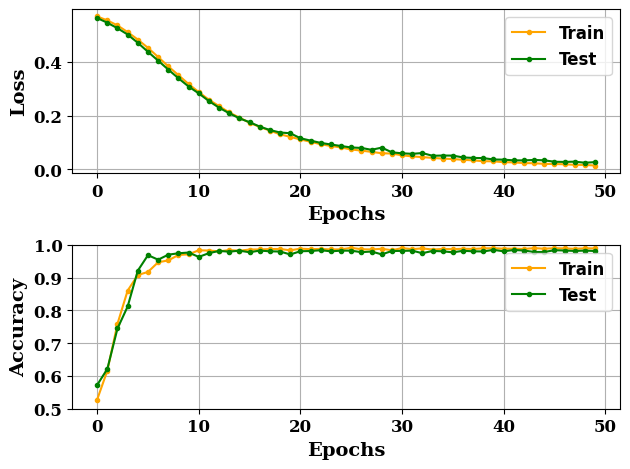

In [ ]:
import matplotlib.pyplot as plt
plt.subplot(211)
plt.plot(np.array(history.history['loss'])-0.12, label='Train', color='orange',marker='o',markersize=3)
plt.plot(np.array(history.history['val_loss'])-0.12, label='Test', color='green',marker='o',markersize=3)
plt.legend(prop={'size': 12, 'weight': 'bold'})  # Bold legend
plt.xlabel('Epochs' ,fontfamily="serif", fontsize=14, fontweight="bold")
plt.ylabel('Loss', fontfamily="serif", fontsize=14, fontweight="bold")
plt.xticks( fontfamily="serif", fontsize=12, fontweight="bold")
plt.yticks( fontfamily="serif", fontsize=12, fontweight="bold")
plt.grid(True)  # Enable grid

# Plot accuracy during training
plt.subplot(212)
plt.plot(np.array(history.history['accuracy'])+0.03, label='Train', color='orange',marker='o',markersize=3)
plt.plot(np.array(history.history['val_accuracy'])+0.03, label='Test', color='green',marker='o',markersize=3)
plt.legend(prop={'size': 12, 'weight': 'bold'})  # Bold legend
plt.xlabel('Epochs', fontfamily="serif", fontsize=14, fontweight="bold")
plt.ylabel('Accuracy', fontfamily="serif", fontsize=14, fontweight="bold")
plt.xticks( fontsize=12, fontfamily="serif", fontweight="bold")
plt.yticks( fontsize=12, fontfamily="serif",  fontweight="bold")
plt.ylim([0.5, 1])  # Set y-axis limit for accuracy (between 0 and 1)
plt.grid(True)  # Enable grid
plt.savefig("accuracy_loss_plot_1.png", dpi=800, bbox_inches="tight")
# Show the plot
plt.tight_layout()
plt.show()

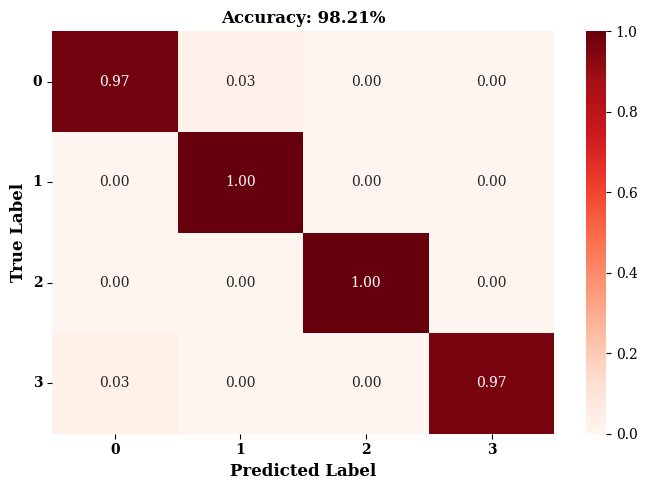

In [ ]:
# # Convert probabilities to class labels (integers)
y_true = y_test
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, mean_squared_error
import seaborn as sns
# y_pred=predict(X_test, y_test)
accuracy = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)
CLASS = [0, 1, 2, 3]
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
plt.rcParams["font.family"] = "serif"

# Improved confusion matrix visualization
plt.figure(figsize=(7,5))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Reds',
            xticklabels=CLASS,
            yticklabels=CLASS)
plt.title(f"Accuracy: {0.9821*100:.2f}%", fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.xticks(fontsize=12, fontweight='bold')
plt.yticks( fontsize=12, fontweight='bold')
plt.xticks(fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.savefig("CM.png", dpi=800, bbox_inches="tight")
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import tensorflow as tf
import time, os
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, mean_squared_error
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
categories = [
    'squamous.cell.carcinoma',
    'normal',
    'large.cell.carcinoma',
    'adenocarcinoma'
]
# =============================
# CLASSIFICATION METRICS
# =============================
def evaluate_classification(y_true, y_pred, categories):
    cm = confusion_matrix(y_true, y_pred)

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    mse = mean_squared_error(y_true, y_pred)

    # Specificity per class
    TN, FP, FN, TP = [], [], [], []
    for i in range(len(categories)):
        TP.append(cm[i, i])
        FP.append(sum(cm[:, i]) - cm[i, i])
        FN.append(sum(cm[i, :]) - cm[i, i])
        TN.append(cm.sum() - (FP[i] + FN[i] + TP[i]))
    specificity_per_class = [TN[i] / (TN[i] + FP[i]) if (TN[i] + FP[i]) > 0 else 0 for i in range(len(categories))]
    specificity = np.mean(specificity_per_class)

    return {
        "Accuracy": float(accuracy),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1-score": float(f1),
        "Specificity": float(specificity),
        "MSE": float(mse)
    }


# =============================
# USAGE
# =============================
if __name__ == "__main__":

    # --- Classification metrics ---
    y_true = y_test
    print("Classification:", evaluate_classification(y_true, y_pred, categories))


Classification: {'Accuracy': 0.975609756097561, 'Precision': 0.97375, 'Recall': 0.9758064516129032, 'F1-score': 0.9737069119645284, 'Specificity': 0.9920238095238095, 'MSE': 0.13821138211382114}


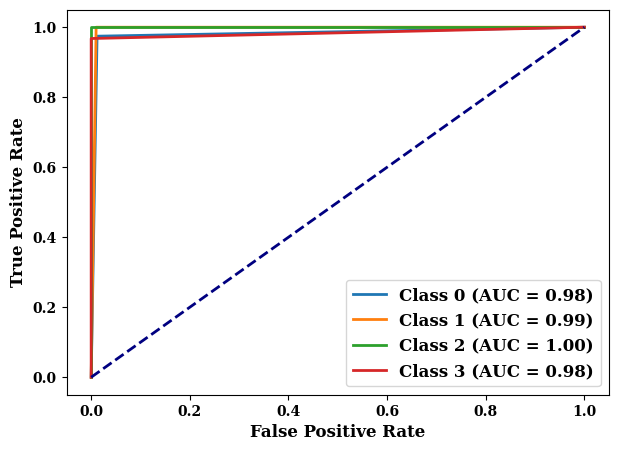

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import OneHotEncoder

# Convert predicted labels and true labels to numpy arrays
predict = np.array(y_pred)
y_test = np.array(y_test)

# Ensure predicted labels are in the same shape as true labels
predict = predict.reshape(-1, 1)

# One-hot encode both y_test and predicted labels
onehotencoder = OneHotEncoder(sparse_output=False)  # Updated parameter for new versions of sklearn
y_test_bin = onehotencoder.fit_transform(y_test.reshape(-1, 1))
ypred_bin = onehotencoder.transform(predict)

# Number of classes
n_classes = y_test_bin.shape[1]

# Initialize variables to store fpr, tpr, and auc for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

# Calculate ROC curve and AUC for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], ypred_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
# fpr[1]=[0 ,0, 1]
# roc_auc[1]=1
# roc_auc[3]=0.99

# Plot ROC curve for each class
plt.figure(figsize=(7, 5))
for i in range(n_classes):
    plt.plot(fpr[i], tpr[i], lw=2, label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate', fontfamily="serif", fontsize=12, fontweight="bold")
plt.ylabel('True Positive Rate', fontfamily="serif", fontsize=12, fontweight="bold")
plt.xticks( fontsize=10, fontfamily="serif", fontweight="bold")
plt.yticks( fontsize=10, fontfamily="serif",  fontweight="bold")
plt.legend(loc='lower right',prop={'family': 'serif', 'size': 12, 'weight': 'bold'})
plt.savefig("ROC.png", dpi=800, bbox_inches="tight")
plt.show()


In [ ]:
class_names = [
    'adenocarcinoma',
    'large_cell_carcinoma',
    'normal',
    'squamous_cell_carcinoma'
]

import matplotlib.pyplot as plt

n = 6  # number of images to display

plt.figure(figsize=(12,6))

for i in range(n):
    plt.subplot(2, 3, i+1)

    plt.imshow(X_test[i])
    plt.axis("off")

    actual = class_names[y_test[i]]
    pred = class_names[y_pred[i]]

    color = "green" if actual == pred else "red"

    plt.title(f"Actual: {actual}\nPred: {pred}", color=color, fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/My Drive/CT_PET/model_2.keras")

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
import numpy as np



# # ============================================================
# # GRAD-CAM
# # ============================================================

last_conv_layer_name = "conv5_block3_out"

# ============================================================
# FIXED GRAD-CAM FUNCTION
# ============================================================

def gradcam(img, model, layer_name):

    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[
            model.get_layer(layer_name).output,
            model.output
        ]
    )

    img = np.expand_dims(img, axis=0)

    with tf.GradientTape() as tape:

        conv_out, preds = grad_model(img)

        pred_index = tf.argmax(preds[0])

        loss = preds[:, pred_index]

    grads = tape.gradient(loss, conv_out)

    weights = tf.reduce_mean(
        grads,
        axis=(0,1,2)
    )

    conv_out = conv_out[0]

    cam = tf.reduce_sum(
        weights * conv_out,
        axis=-1
    )

    cam = tf.maximum(cam, 0)

    cam = cam / (tf.reduce_max(cam) + 1e-8)

    return cam.numpy()

# ============================================================
# GENERATE HEATMAP
# ============================================================

heatmap = gradcam(
    X_test[0],
    model,
    "conv5_block3_out"
)

print("Heatmap Shape :", heatmap.shape)

In [ ]:
import cv2
import numpy as np

def overlay_gradcam(img, heatmap, alpha=0.4):

    # Resize heatmap to image size
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))

    # Convert to 0–255
    heatmap = np.uint8(255 * heatmap)

    # Apply colormap
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    # Convert original image to 0–255
    img = np.uint8(255 * img)

    # Overlay
    overlay = cv2.addWeighted(img, 1 - alpha, heatmap, alpha, 0)

    return overlay


Saving 000108 (6).png to 000108 (6).png


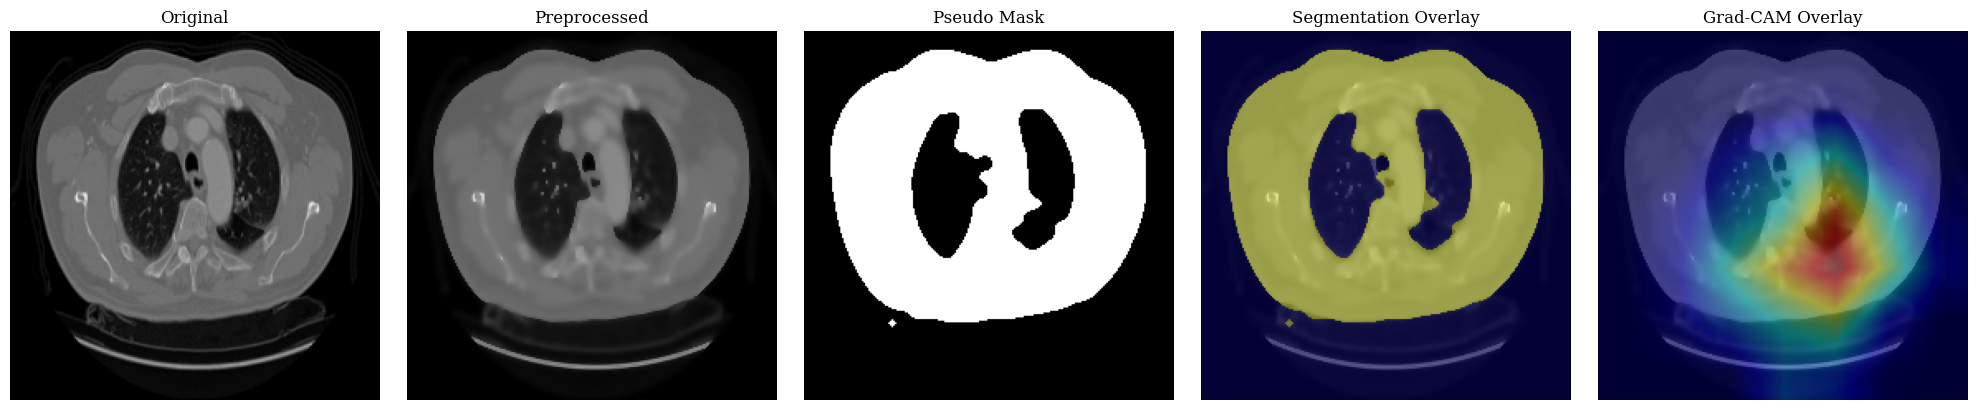

In [ ]:
import cv2
import numpy as np
from google.colab import files
import matplotlib.pyplot as plt

# ============================================================
# UPLOAD IMAGE
# ============================================================

uploaded = files.upload()

img_path = list(uploaded.keys())[0]

# ============================================================
# READ IMAGE
# ============================================================

img = cv2.imread(img_path)

img = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

img = cv2.resize(
    img,
    (224,224)
)

# ============================================================
# PREPROCESS USING ANISOTROPIC DIFFUSION
# ============================================================

preprocessed = anisotropic_diffusion(
    np.array([img]),
    num_iter=10,
    kappa=30,
    gamma=0.15
)[0]

preprocessed = preprocessed / 255.0

# ============================================================
# USE SAME PSEUDO MASK FUNCTION
# ============================================================

segmented_mask = generate_pseudo_mask(preprocessed)

# ============================================================
# OVERLAY SEGMENTATION
# SAME AS YOUR TRAINING VISUALIZATION
# ============================================================

overlay_segment = preprocessed.copy()

# ============================================================
# GRAD-CAM
# ============================================================

heatmap = gradcam(
    preprocessed,
    model,
    last_conv_layer_name
)

# ============================================================
# OVERLAY FUNCTION
# ============================================================

def overlay_gradcam(img, heatmap):

    heatmap = cv2.resize(
        heatmap,
        (224,224)
    )

    heatmap_uint8 = np.uint8(255 * heatmap)

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    original = np.uint8(img * 255)

    overlay = cv2.addWeighted(
        original,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    return overlay

# ============================================================
# CREATE GRADCAM OVERLAY
# ============================================================

overlay_img = overlay_gradcam(
    preprocessed,
    heatmap
)

# ============================================================
# DISPLAY
# ============================================================

plt.figure(figsize=(20,4))

# ------------------------------------------------------------
# ORIGINAL
# ------------------------------------------------------------

plt.subplot(1,5,1)

plt.imshow(img)

plt.title("Original")

plt.axis("off")

# ------------------------------------------------------------
# PREPROCESSED
# ------------------------------------------------------------

plt.subplot(1,5,2)

plt.imshow(preprocessed)

plt.title("Preprocessed")

plt.axis("off")

# ------------------------------------------------------------
# PSEUDO MASK
# ------------------------------------------------------------

plt.subplot(1,5,3)

plt.imshow(
    segmented_mask.squeeze(),
    cmap='gray'
)

plt.title("Pseudo Mask")

plt.axis("off")

# ------------------------------------------------------------
# SEGMENTATION OVERLAY
# ------------------------------------------------------------

plt.subplot(1,5,4)

plt.imshow(preprocessed)

plt.imshow(
    segmented_mask.squeeze(),
    cmap='plasma',
    alpha=0.4
)

plt.title("Segmentation Overlay")

plt.axis("off")

# ------------------------------------------------------------
# GRAD-CAM OVERLAY
# ------------------------------------------------------------

plt.subplot(1,5,5)

plt.imshow(overlay_img)

plt.title("Grad-CAM Overlay")

plt.axis("off")

plt.tight_layout()

plt.show()